# F&B Sales Analytics: аналіз продажів мережі кав'ярень

**Індонезія · 3 торгові точки · січень–вересень 2025**

## Про проєкт
Мережа кав'ярень у `SHOP001`, `SHOP002` і `SHOP003` зберігає кожен продаж у касовій системі (POS). У цьому ноутбуці я аналізую ці дані: **53 820 чеків, 61 973 продані позиції, 96 товарів у меню**. Валюта: індонезійська рупія (IDR).

Мета: зрозуміти, **де, коли і на чому** бізнес заробляє, і запропонувати кілька ідей для зростання.

## На які питання відповідає аналіз
1. Скільки заробляє мережа і який середній чек?
2. Чим відрізняються три заклади?
3. Як змінювалися продажі по місяцях і що сталося в квітні?
4. У які дні й години найбільше покупців?
5. Які категорії та продукти приносять найбільше доходу?
6. Як працює програма лояльності?
7. Як клієнти платять?
8. Що купують разом в одному чеку?

## Дані
| Файл | Що в ньому |
|---|---|
| `Transactions.csv` | один рядок = один чек (заклад, дата, час, сума, список товарів, спосіб оплати) |
| `Products.csv` | довідник меню (назва, варіант, категорія, ціна) |

In [51]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch


BLUE = '#1F4E79'
LIGHT_BLUE = '#8FB8DE'
ORANGE = '#E8742A'
GREY = '#9A9A9A'
GREEN = '#2E8B57'
RED = '#C0392B'

# кожен заклад має свій колір у всіх графіках
OUTLET_COLORS = {'SHOP001': BLUE, 'SHOP002': ORANGE, 'SHOP003': LIGHT_BLUE}

In [33]:
# шукаю папку з файлами: поруч із ноутбуком або в ../data/
DATA_DIR = None
for folder in ['../data/', 'data/', '']:
    if os.path.exists(folder + 'Transactions.csv'):
        DATA_DIR = folder
        break
if DATA_DIR is None:
    raise FileNotFoundError('Не знайшов Transactions.csv. Покладіть файлиф в папку data/ або поруч із ноутбуком.')

products = pd.read_csv(DATA_DIR + 'Products.csv')
transactions = pd.read_csv(DATA_DIR + 'Transactions.csv')

print(f'Products: {products.shape[0]} рядків, {products.shape[1]} колонок')
print(f'Transactions: {transactions.shape[0]} рядків, {transactions.shape[1]} колонок')
display(products.head(3))
display(transactions.head(3))

Products: 96 рядків, 6 колонок
Transactions: 53820 рядків, 11 колонок


,ProductId,ProductName,Variant,Category,Price,Description
0,1,Add on Aren,-,Add on,0,"Tambahan sirup gula aren murni, memberikan ras..."
1,2,Add on Simple Syrup,-,Add on,0,Tambahan sirup gula sederhana (air dan gula) s...
2,3,Air Mineral,-,Other,5000,Air minum murni dalam kemasan


,Outlet,Date,Time,NetSales,Tax,TotalAmount,ReceiptNumber,Items,TotalItem,PaymentMethod,UseLoyaltyCard
0,SHOP001,2025-01-02,07:01:05,20720.721,2279.279,23000,SHOP001JAN2500001,Basic Latte (Ice Arabica),1,BCA,0
1,SHOP001,2025-01-02,07:04:11,18018.018,1981.982,20000,SHOP001JAN2500002,BLACK (Houseblend),1,BCA,0
2,SHOP002,2025-01-02,07:10:46,39639.640,4360.360,44000,SHOP002JAN2500001,"Friendly Coffee (Hot), Shakencano",2,Cash,0


In [34]:
# перетворюю дату й час та додаю зручні колонки
transactions['Date'] = pd.to_datetime(transactions['Date'])
transactions['Month'] = transactions['Date'].dt.to_period('M').astype(str)
transactions['Weekday_num'] = transactions['Date'].dt.dayofweek          # 0 = понеділок
transactions['Hour'] = pd.to_datetime(transactions['Time'], format='%H:%M:%S').dt.hour

# перевірки якості
print('Пропуски в Products:', products.isna().sum().sum())
print('Пропуски в Transactions:', transactions.isna().sum().sum())
print('Дублікати номерів чеків:', transactions['ReceiptNumber'].duplicated().sum())
print('Від\'ємні суми чеків:', (transactions['TotalAmount'] < 0).sum())
print('Чеки з нульовою сумою:', (transactions['TotalAmount'] == 0).sum())
print('Заклади:', sorted(transactions['Outlet'].unique()))
print('Способи оплати:', sorted(transactions['PaymentMethod'].unique()))
print('Період:', transactions['Date'].min().date(), '—', transactions['Date'].max().date())

Пропуски в Products: 0
Пропуски в Transactions: 0
Дублікати номерів чеків: 0
Від'ємні суми чеків: 0
Чеки з нульовою сумою: 1733
Заклади: ['SHOP001', 'SHOP002', 'SHOP003']
Способи оплати: ['BCA', 'Cash', 'GoFood']
Період: 2025-01-02 — 2025-09-30


C:\Users\Дмитро\AppData\Local\Temp\ipykernel_12148\863099258.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  transactions['Weekday_num'] = transactions['Date'].dt.dayofweek          # 0 = понеділок


 Чеки з **нульовою сумою** не помилка: це чеки, оплачені програмою лояльності (клієнт отримує позицію безкоштовно). Їх я розберу в окремому розділі.

## 3. Підготовка таблиці проданих позицій
У чеку всі товари записані в одному полі `Items` через кому, наприклад `BLACK (Arabica), Americano (Hot Arabica)`. Щоб рахувати продажі по продуктах і категоріях, я:
1. складаю повну назву товару в довіднику (`Назва (Варіант)`),
2. розділяю список товарів у чеку на окремі рядки (`explode`),
3. приєдную довідник, щоб отримати категорію та ціну.

In [35]:
# повна назва товару, як вона записана в чеках
products['FullName'] = np.where(
    products['Variant'] == '-',
    products['ProductName'],
    products['ProductName'] + ' (' + products['Variant'] + ')'
)

# один рядок = одна позиція в чеку
items_df = transactions[['ReceiptNumber', 'Outlet', 'Month', 'PaymentMethod', 'UseLoyaltyCard', 'TotalItem', 'Items']].copy()
items_df['Item'] = items_df['Items'].str.split(', ')
items_df = items_df.explode('Item')

# приєдную категорію та ціну з довідника
items_df = items_df.merge(
    products[['ProductId', 'FullName', 'ProductName', 'Category', 'Price']],
    left_on='Item', right_on='FullName', how='left'
)

# якщо клієнт платив карткою лояльності, позиція безкоштовна
items_df['Revenue'] = np.where(items_df['UseLoyaltyCard'] == 1, 0, items_df['Price'])
items_df['Loyalty_Discount'] = np.where(items_df['UseLoyaltyCard'] == 1, items_df['Price'], 0)

print(f'Позицій у таблиці: {len(items_df):,} (сума TotalItem у чеках: {transactions["TotalItem"].sum():,})')
print(f'Товарів, яких не знайшли в довіднику: {items_df["ProductId"].isna().sum()}')

Позицій у таблиці: 61,973 (сума TotalItem у чеках: 61,973)
Товарів, яких не знайшли в довіднику: 0


### Перевірка: чи збігаються гроші
Найважливіше правило аналітика: **цифри з різних джерел мають сходитися**. Порівнюю дохід, який я порахував з окремих товарів, із сумами в заголовках чеків.

In [36]:
income_from_items = items_df['Revenue'].sum()
income_from_receipts = transactions['TotalAmount'].sum()
difference = income_from_items - income_from_receipts

print(f'Дохід за позиціями (ціни з довідника):  {income_from_items:,.0f} IDR')
print(f'Дохід за чеками (поле TotalAmount):     {income_from_receipts:,.0f} IDR')
print(f'Різниця:                                {difference:,.0f} IDR')

if difference == 0:
    print('Суми збігаються, розбивка чеків на позиції виконана правильно.')
else:
    print('Увага: є розбіжність, потрібно перевірити назви товарів у чеках.')

Дохід за позиціями (ціни з довідника):  1,315,276,000 IDR
Дохід за чеками (поле TotalAmount):     1,315,276,000 IDR
Різниця:                                0 IDR
Суми збігаються, розбивка чеків на позиції виконана правильно.


**Висновок:** суми збігаються до рупії, тож усі наступні розрахунки по категоріях і продуктах можна вважати надійними.

## 4. Загальні показники бізнесу
Починаємо з простих запитань: скільки чеків, скільки грошей і яка типова сума чеку?

Для середнього чеку я беру лише **оплачені** чеки (сума більше нуля). Безкоштовні чеки за лояльністю штучно занижували б середнє.

In [37]:
paid = transactions[transactions['TotalAmount'] > 0]

total_receipts = len(transactions)
total_items = transactions['TotalItem'].sum()
total_revenue = transactions['TotalAmount'].sum()
avg_check_paid = paid['TotalAmount'].mean()
median_check_paid = paid['TotalAmount'].median()

print(f'Усього чеків:               {total_receipts:,}')
print(f'Продано позицій:            {total_items:,}  (у середньому {total_items / total_receipts:.2f} на чек)')
print(f'Дохід (TotalAmount):        {total_revenue:,.0f} IDR')
print(f'Середній оплачений чек:     {avg_check_paid:,.0f} IDR')
print(f'Медіанний оплачений чек:    {median_check_paid:,.0f} IDR')

Усього чеків:               53,820
Продано позицій:            61,973  (у середньому 1.15 на чек)
Дохід (TotalAmount):        1,315,276,000 IDR
Середній оплачений чек:     25,252 IDR
Медіанний оплачений чек:    23,000 IDR


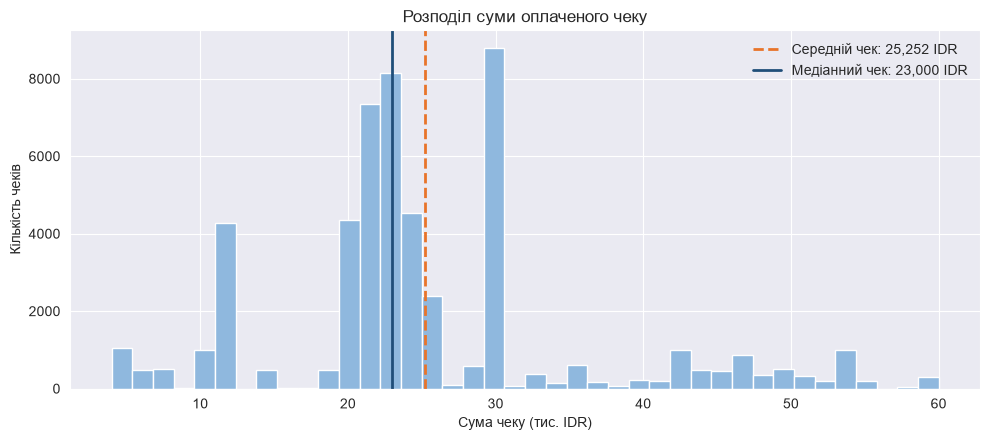

In [38]:
fig, ax = plt.subplots(figsize=(10, 4.5))

ax.hist(paid['TotalAmount'] / 1000, bins=40, color=LIGHT_BLUE, edgecolor='white')
ax.axvline(avg_check_paid / 1000, color=ORANGE, linewidth=2, linestyle='--', label=f'Середній чек: {avg_check_paid:,.0f} IDR')
ax.axvline(median_check_paid / 1000, color=BLUE, linewidth=2, label=f'Медіанний чек: {median_check_paid:,.0f} IDR')

ax.set_title('Розподіл суми оплаченого чеку')
ax.set_xlabel('Сума чеку (тис. IDR)')
ax.set_ylabel('Кількість чеків')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Висновок:** гістограма показує, скільки чеків припадає на кожну суму. Високі стовпчики відповідають цінам популярних напоїв, а правий «хвіст» це чеки з двома позиціями. Середній і медіанний чек близькі, тож «типовий» клієнт витрачає приблизно 23–25 тис. IDR (один напій).

## 5. Порівняння торгових точок
Скільки заробляє кожен заклад і чи відрізняється середній чек?

In [39]:
outlet_df = transactions.groupby('Outlet').agg(
    Receipts=('ReceiptNumber', 'count'),
    Items_Sold=('TotalItem', 'sum'),
    Revenue=('TotalAmount', 'sum')
).sort_values('Revenue', ascending=False)

outlet_df['Avg_Check_Paid'] = paid.groupby('Outlet')['TotalAmount'].mean()
outlet_df['Revenue_Share_%'] = outlet_df['Revenue'] / total_revenue * 100

display(outlet_df)

,Receipts,Items_Sold,Revenue,Avg_Check_Paid,Revenue_Share_%
Outlet,,,,,
SHOP001,26250,30249,644108000,25274.004316,48.971319
SHOP003,16753,19341,409504000,25292.075845,31.134454
SHOP002,10817,12383,261664000,25133.416579,19.894228


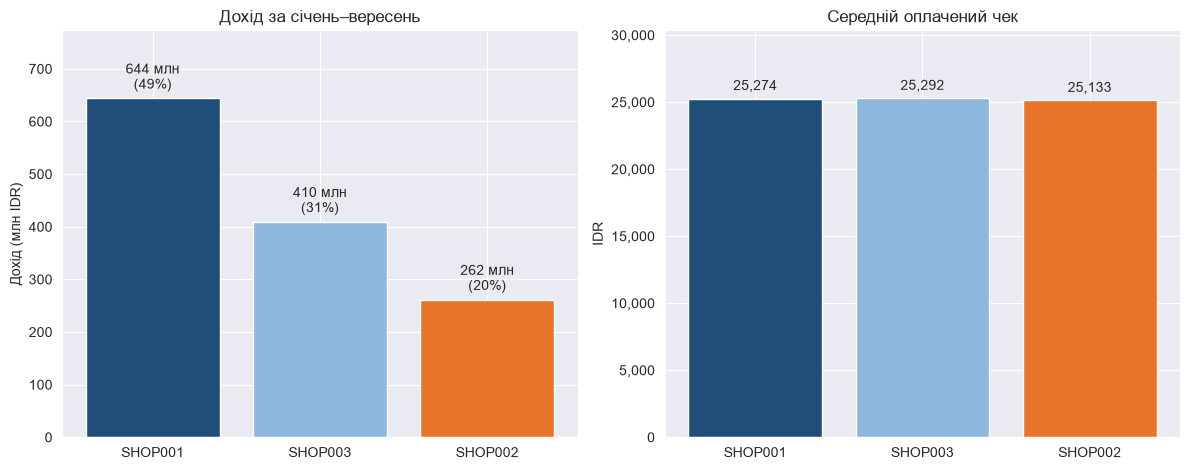

In [40]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
colors = [OUTLET_COLORS[o] for o in outlet_df.index]

# зліва: дохід
bars = ax1.bar(outlet_df.index, outlet_df['Revenue'] / 1e6, color=colors)
labels = [f'{r / 1e6:,.0f} млн\n({s:.0f}%)' for r, s in zip(outlet_df['Revenue'], outlet_df['Revenue_Share_%'])]
ax1.bar_label(bars, labels=labels, padding=4)
ax1.set_ylim(0, outlet_df['Revenue'].max() / 1e6 * 1.2)
ax1.set_title('Дохід за січень–вересень')
ax1.set_ylabel('Дохід (млн IDR)')

# справа: середній чек
bars = ax2.bar(outlet_df.index, outlet_df['Avg_Check_Paid'], color=colors)
ax2.bar_label(bars, labels=[f'{v:,.0f}' for v in outlet_df['Avg_Check_Paid']], padding=4)
ax2.set_ylim(0, outlet_df['Avg_Check_Paid'].max() * 1.2)
ax2.set_title('Середній оплачений чек')
ax2.set_ylabel('IDR')
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))

plt.tight_layout()
plt.show()

**Висновок:**
- **SHOP001 приносить майже половину доходу мережі (≈49%)**, SHOP003 ≈31%, SHOP002 ≈20%.
- Середній чек у всіх трьох закладах майже однаковий (різниця менша за 2%). Отже, різниця в доході пояснюється **кількістю покупців**, а не тим, скільки вони витрачають.
- Щоб збільшити дохід SHOP002 і SHOP003, треба працювати з потоком гостей (локація, маркетинг, години роботи), а не з цінами.

## 6. Динаміка продажів по місяцях
Як змінювався дохід від січня до вересня? Праворуч у таблиці `MoM_%` це зміна відносно попереднього місяця (month-over-month).

In [41]:
month_df = transactions.groupby('Month').agg(
    Receipts=('ReceiptNumber', 'count'),
    Revenue=('TotalAmount', 'sum')
)
month_df['Avg_Check_Paid'] = paid.groupby('Month')['TotalAmount'].mean()
month_df['MoM_%'] = month_df['Revenue'].pct_change() * 100

display(month_df)

,Receipts,Revenue,Avg_Check_Paid,MoM_%
Month,,,,
2025-01,5372,131233000,25266.268772,NaN
2025-02,6124,149180000,25156.829680,13.675676
2025-03,6255,152385000,25096.343874,2.148411
2025-04,4439,110195000,25656.577416,-27.686452
2025-05,5426,132639000,25144.834123,20.367530
2025-06,7530,182769000,25133.250825,37.794314
2025-07,7176,176286000,25364.892086,-3.547100
2025-08,5972,145624000,25260.017346,-17.393327
2025-09,5526,134965000,25302.774653,-7.319535


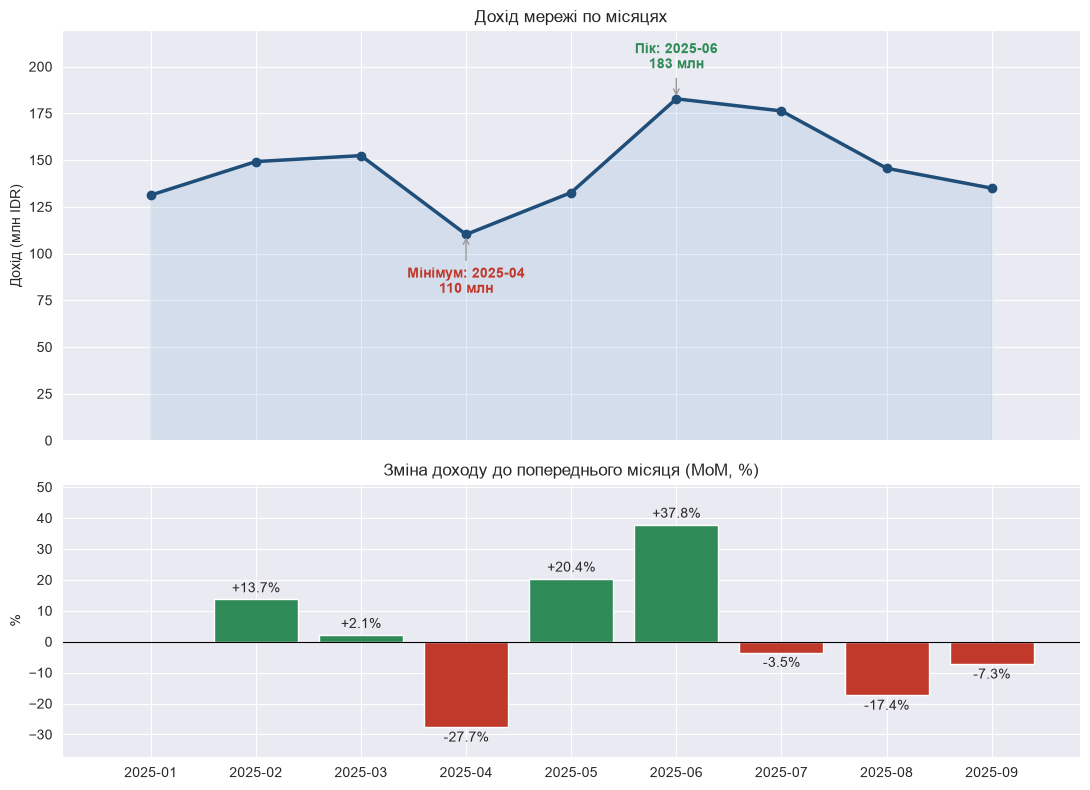

In [42]:
months = month_df.index.tolist()
x = np.arange(len(months))
revenue_m = month_df['Revenue'] / 1e6

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True, gridspec_kw={'height_ratios': [3, 2]})

# верхній графік: дохід
ax1.plot(x, revenue_m, marker='o', linewidth=2.5, color=BLUE)
ax1.fill_between(x, revenue_m, color=LIGHT_BLUE, alpha=0.25)
best = revenue_m.idxmax()
worst = revenue_m.idxmin()
ax1.annotate(f'Пік: {best}\n{revenue_m[best]:.0f} млн', xy=(months.index(best), revenue_m[best]),
             xytext=(0, 22), textcoords='offset points', ha='center',
             arrowprops=dict(arrowstyle='->', color=GREY), color=GREEN, fontweight='bold')
ax1.annotate(f'Мінімум: {worst}\n{revenue_m[worst]:.0f} млн', xy=(months.index(worst), revenue_m[worst]),
             xytext=(0, -42), textcoords='offset points', ha='center',
             arrowprops=dict(arrowstyle='->', color=GREY), color=RED, fontweight='bold')
ax1.set_ylim(0, revenue_m.max() * 1.2)
ax1.set_title('Дохід мережі по місяцях')
ax1.set_ylabel('Дохід (млн IDR)')

# нижній графік: зміна до попереднього місяця
mom = month_df['MoM_%']
bar_colors = [GREEN if v >= 0 else RED for v in mom.fillna(0)]
bars = ax2.bar(x, mom.fillna(0), color=bar_colors)
ax2.bar_label(bars, labels=['' if np.isnan(v) else f'{v:+.1f}%' for v in mom], padding=3)
ax2.axhline(0, color='black', linewidth=0.8)
ax2.set_ylim(mom.min() * 1.35, mom.max() * 1.35)
ax2.set_title('Зміна доходу до попереднього місяця (MoM, %)')
ax2.set_ylabel('%')
ax2.set_xticks(x)
ax2.set_xticklabels(months)

plt.tight_layout()
plt.show()

**Висновок:**
- **Червень це пік року (≈183 млн IDR, +37,8% до травня)**, червень і липень найсильніші місяці.
- **Квітень це провал: ≈110 млн IDR, −27,7%** до березня.
- Після літнього піку дохід знижується: серпень −17,4%, вересень −7,3%.
- Середній чек майже не змінюється (коливання менші за 3%), тож зміни доходу залежать від **кількості чеків**, а не від того, скільки платить клієнт.

### Що сталося в квітні?
Подивимося, чи просіли всі заклади однаково.

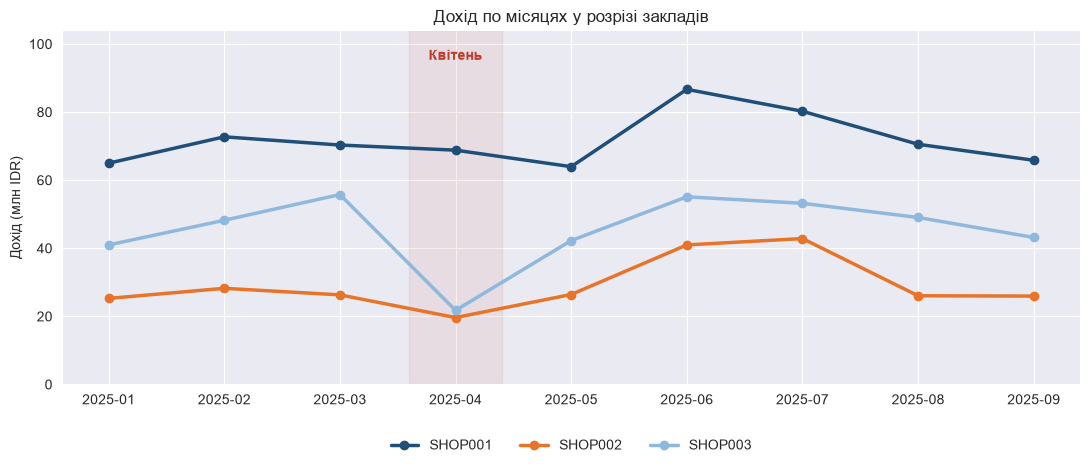

In [43]:
revenue_by_outlet = transactions.pivot_table(index='Month', columns='Outlet', values='TotalAmount', aggfunc='sum') / 1e6
april = list(revenue_by_outlet.index).index('2025-04')

fig, ax = plt.subplots(figsize=(11, 4.8))
for outlet in revenue_by_outlet.columns:
    ax.plot(x, revenue_by_outlet[outlet], marker='o', linewidth=2.5, color=OUTLET_COLORS[outlet], label=outlet)

ax.axvspan(april - 0.4, april + 0.4, color=RED, alpha=0.08)
ax.set_ylim(0, revenue_by_outlet.values.max() * 1.2)
ax.text(april, revenue_by_outlet.values.max() * 1.1, 'Квітень', ha='center', color=RED, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(months)
ax.set_title('Дохід по місяцях у розрізі закладів')
ax.set_ylabel('Дохід (млн IDR)')
ax.legend(frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

In [44]:
# скільки днів у місяці заклад мав продажі і який дохід на один такий день
active_days = transactions.groupby(['Month', 'Outlet'])['Date'].nunique().unstack()
revenue_per_day = (revenue_by_outlet * 1e6 / active_days) / 1000

print('Днів із продажами:')
display(active_days)
print('Дохід на один день із продажами (тис. IDR):')
display(revenue_per_day)

print()
for shop in revenue_by_outlet.columns:
    change = (revenue_by_outlet.loc['2025-04', shop] / revenue_by_outlet.loc['2025-03', shop] - 1) * 100
    print(f'{shop}: дохід у квітні {change:+.0f}% до березня; днів із продажами {active_days.loc["2025-03", shop]} -> {active_days.loc["2025-04", shop]}')

Днів із продажами:


Outlet,SHOP001,SHOP002,SHOP003
Month,,,
2025-01,30,30,30
2025-02,28,28,28
2025-03,31,31,31
2025-04,30,30,30
2025-05,31,31,31
2025-06,30,30,30
2025-07,31,31,31
2025-08,31,31,31
2025-09,30,30,30


Дохід на один день із продажами (тис. IDR):


Outlet,SHOP001,SHOP002,SHOP003
Month,,,
2025-01,2166.366667,842.200000,1365.866667
2025-02,2597.464286,1008.214286,1722.178571
2025-03,2268.225806,848.483871,1798.935484
2025-04,2293.733333,654.600000,724.833333
2025-05,2063.322581,852.032258,1363.322581
2025-06,2889.233333,1365.966667,1837.100000
2025-07,2588.290323,1382.096774,1716.258065
2025-08,2275.548387,840.064516,1581.935484
2025-09,2194.733333,864.933333,1439.166667



SHOP001: дохід у квітні -2% до березня; днів із продажами 31 -> 30
SHOP002: дохід у квітні -25% до березня; днів із продажами 31 -> 30
SHOP003: дохід у квітні -61% до березня; днів із продажами 31 -> 30


**Висновок:** провал у квітні **не однаковий для всіх закладів**: `SHOP001` майже не змінився (≈70 → 69 млн IDR), а `SHOP003` просів приблизно з 56 до 22 млн, `SHOP002` з 26 до 20 млн. Таблиця днів із продажами вище показує, чи заклад працював усі дні. Якщо кількість днів зменшилась, причина в тимчасовому закритті, якщо ні, то просіла кількість гостей. **Причину в самих даних встановити неможливо**, тому її варто уточнити в бізнесу (ремонт, свята, акції конкурентів).

## 7. Коли купують: дні тижня та години
Теплова карта показує дохід для кожної комбінації «день тижня × година». Чим темніший колір, тим більше грошей.

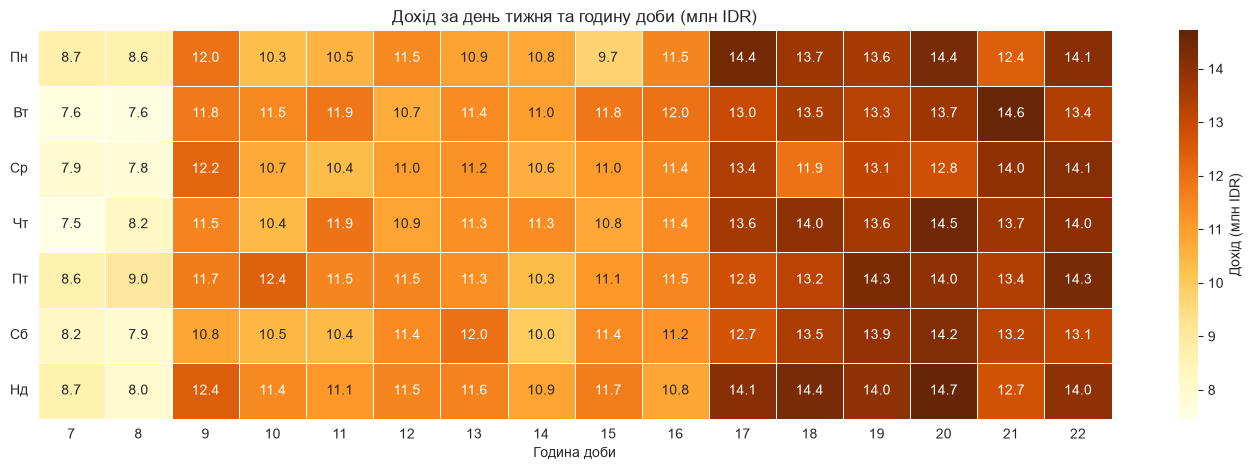

In [45]:
week_labels = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Нд']

heat = transactions.pivot_table(index='Weekday_num', columns='Hour', values='TotalAmount', aggfunc='sum') / 1e6
heat.index = week_labels

fig, ax = plt.subplots(figsize=(14, 4.8))
sns.heatmap(heat, annot=True, fmt='.1f', cmap='YlOrBr', linewidths=0.5,
            cbar_kws={'label': 'Дохід (млн IDR)'}, ax=ax)
ax.grid(False)
ax.set_title('Дохід за день тижня та годину доби (млн IDR)')
ax.set_xlabel('Година доби')
ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

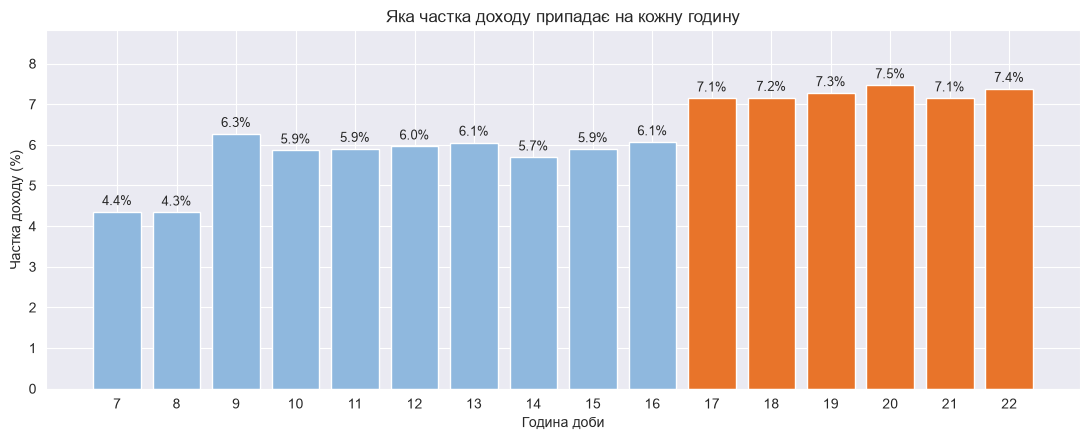

Найсильніші години: [17, 18, 19, 20, 21, 22]


In [46]:
hour_revenue = transactions.groupby('Hour')['TotalAmount'].sum()
hour_share = hour_revenue / hour_revenue.sum() * 100

top_hours = hour_share.nlargest(6).index
bar_colors = [ORANGE if h in top_hours else LIGHT_BLUE for h in hour_share.index]

fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.bar(hour_share.index, hour_share.values, color=bar_colors)
ax.bar_label(bars, labels=[f'{v:.1f}%' for v in hour_share.values], padding=3, fontsize=9)
ax.set_xticks(hour_share.index)
ax.set_ylim(0, hour_share.max() * 1.18)
ax.set_title('Яка частка доходу припадає на кожну годину')
ax.set_xlabel('Година доби')
ax.set_ylabel('Частка доходу (%)')
plt.tight_layout()
plt.show()

print('Найсильніші години:', sorted(top_hours.tolist()))

**Висновок:**
- **День тижня майже не впливає на дохід:** будні та вихідні дуже схожі.
- **Година доби впливає сильно.** Найслабші години: **7–8 ранку** (≈7,5–9 млн IDR у клітинці карти). Найсильніші: **17–22 години** (≈12–14,7 млн IDR). Вдень (9–16) попит стабільно середній.
- Бізнес по суті «вечірній»: персонал і запаси варто планувати під 17:00–22:00, а ранок можна підсилювати окремою пропозицією (наприклад, кава + випічка).

## 8. Категорії та продукти
Що саме купують і що приносить найбільше грошей. Спочатку категорії: порівняємо **частку в проданих штуках** і **частку в доході**.

In [47]:
cat_df = items_df.groupby('Category').agg(
    Active_SKUs=('ProductId', 'nunique'),
    Units_Sold=('Item', 'count'),
    Revenue=('Revenue', 'sum')
).sort_values('Revenue', ascending=False)

cat_df['Unit_Share_%'] = cat_df['Units_Sold'] / cat_df['Units_Sold'].sum() * 100
cat_df['Revenue_Share_%'] = cat_df['Revenue'] / cat_df['Revenue'].sum() * 100

display(cat_df)

,Active_SKUs,Units_Sold,Revenue,Unit_Share_%,Revenue_Share_%
Category,,,,,
Coffee,34,22422,473259000,36.180272,35.981726
Menu Gedhe,19,12581,343030000,20.300776,26.080458
Other,15,9995,216337000,16.127991,16.448031
Tea,13,8494,173058000,13.705969,13.157543
Snacks,9,5832,91851000,9.410550,6.983401
Add on,4,2649,17741000,4.274442,1.348842


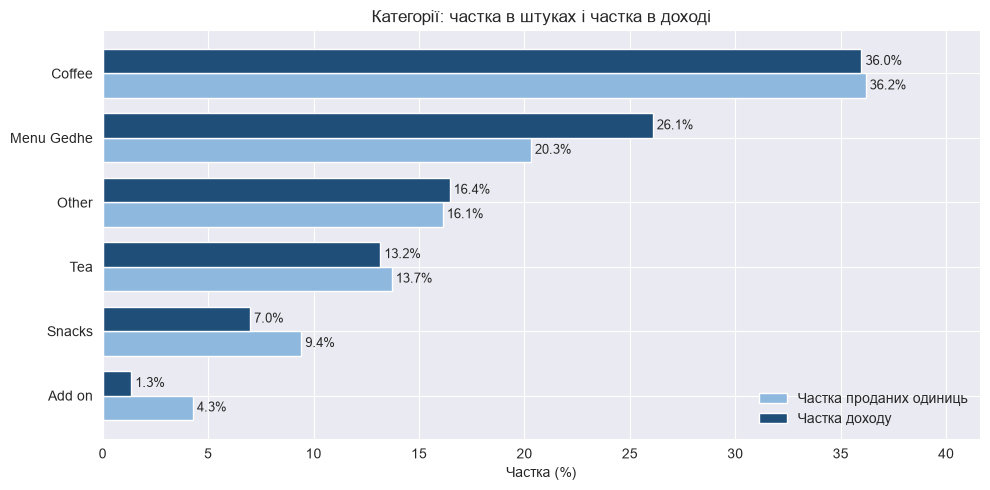

In [48]:
plot_df = cat_df.sort_values('Revenue_Share_%')
y = np.arange(len(plot_df))
h = 0.38

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.barh(y - h / 2, plot_df['Unit_Share_%'], h, color=LIGHT_BLUE, label='Частка проданих одиниць')
bars2 = ax.barh(y + h / 2, plot_df['Revenue_Share_%'], h, color=BLUE, label='Частка доходу')
ax.bar_label(bars1, labels=[f'{v:.1f}%' for v in plot_df['Unit_Share_%']], padding=3, fontsize=9)
ax.bar_label(bars2, labels=[f'{v:.1f}%' for v in plot_df['Revenue_Share_%']], padding=3, fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.set_xlim(0, plot_df[['Unit_Share_%', 'Revenue_Share_%']].values.max() * 1.15)
ax.set_title('Категорії: частка в штуках і частка в доході')
ax.set_xlabel('Частка (%)')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()

**Висновок:**
- **Coffee** лідирує (≈36% і штук, і доходу).
- **Menu Gedhe** (великі напої) це ≈20% проданих штук, але **≈26% доходу**: напої дорожчі, тому категорія заробляє більше, ніж продається.
- **Snacks** навпаки: ≈9% штук, але лише ≈7% доходу, бо позиції дешеві.
- **Add on** (добавки) майже не дають доходу (≈1%).

### Топ-10 продуктів за доходом
Тут я об'єдную варіанти одного напою (Hot, Ice, Arabica тощо) під його загальною назвою.

In [49]:
product_df = items_df.groupby(['ProductName', 'Category']).agg(
    Units_Sold=('Item', 'count'),
    Revenue=('Revenue', 'sum')
).sort_values('Revenue', ascending=False).head(10).reset_index()

display(product_df)

,ProductName,Category,Units_Sold,Revenue
0,Friendly Coffee,Coffee,2721,60099000
1,WHITE,Menu Gedhe,2025,58200000
2,Basic Latte,Coffee,2588,56511000
3,Cappuccino,Coffee,2552,53482000
4,Americano,Coffee,2666,53320000
5,BLACK,Menu Gedhe,1982,39640000
6,Happy Moca,Coffee,1344,39030000
7,Chocolate,Other,1376,33150000
8,Matcha Latte,Other,1289,29640000
9,Black Rice,Other,1320,29279000


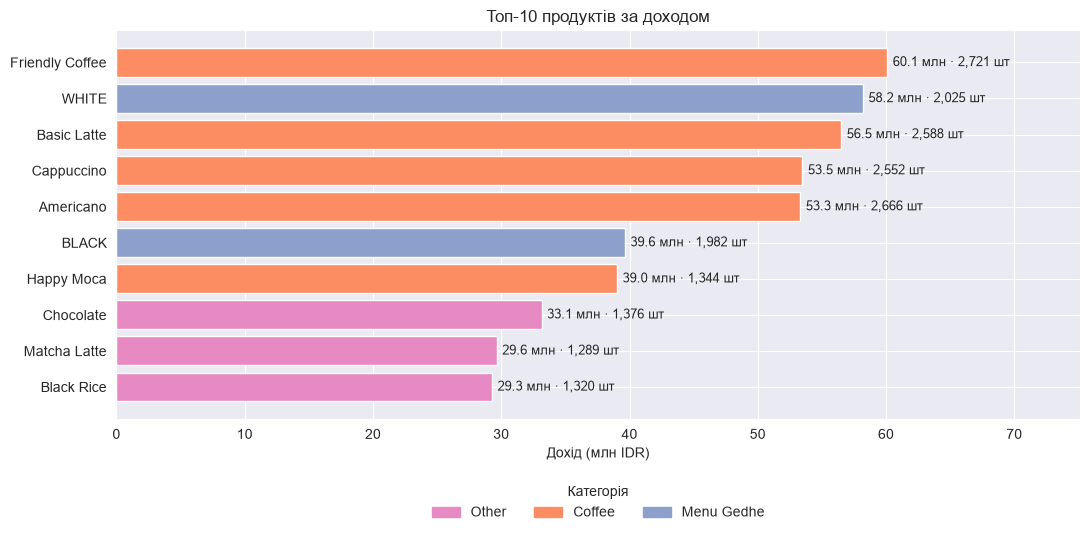

Топ-3 продукти: Friendly Coffee, WHITE, Basic Latte
Топ-10 продуктів дають 34.4% доходу з 68 продуктів у меню.


In [52]:
categories = sorted(items_df['Category'].dropna().unique())
CAT_COLORS = dict(zip(categories, sns.color_palette('Set2', len(categories))))

plot_df = product_df.iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.barh(plot_df['ProductName'], plot_df['Revenue'] / 1e6, color=[CAT_COLORS[c] for c in plot_df['Category']])
ax.bar_label(bars, labels=[f'{r / 1e6:.1f} млн · {u:,} шт' for r, u in zip(plot_df['Revenue'], plot_df['Units_Sold'])], padding=4, fontsize=9)
ax.set_xlim(0, plot_df['Revenue'].max() / 1e6 * 1.25)
ax.set_title('Топ-10 продуктів за доходом')
ax.set_xlabel('Дохід (млн IDR)')
ax.legend(handles=[Patch(color=CAT_COLORS[c], label=c) for c in plot_df['Category'].unique()], title='Категорія', frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=len(plot_df['Category'].unique()))
plt.tight_layout()
plt.show()

top3 = product_df['ProductName'].head(3).tolist()
top10_share = product_df['Revenue'].sum() / items_df['Revenue'].sum() * 100
print(f'Топ-3 продукти: {", ".join(top3)}')
print(f'Топ-10 продуктів дають {top10_share:.1f}% доходу з {items_df["ProductName"].nunique()} продуктів у меню.')

**Висновок:** у топі переважають кавові напої та великі напої Menu Gedhe. Рядок під графіком показує, яку частку доходу дає топ-10: якщо вона невелика, дохід **розподілений рівномірно по меню** і немає одного «рятівного» товару, від якого залежить бізнес.

## 9. Програма лояльності
Якщо клієнт користується карткою лояльності, одна позиція в чеку безкоштовна (сума чеку 0 IDR). Скільки бізнес віддає таким чином і на що?

In [53]:
loyalty_receipts = transactions['UseLoyaltyCard'].sum()
loyalty_value = items_df['Loyalty_Discount'].sum()
catalog_value = items_df['Price'].sum()

print(f'Чеків із карткою лояльності: {loyalty_receipts:,} ({loyalty_receipts / total_receipts * 100:.1f}% усіх чеків)')
print(f'Вартість безкоштовних позицій: {loyalty_value:,.0f} IDR ({loyalty_value / catalog_value * 100:.1f}% від вартості всіх проданих товарів за меню)')

Чеків із карткою лояльності: 1,733 (3.2% усіх чеків)
Вартість безкоштовних позицій: 44,258,000 IDR (3.3% від вартості всіх проданих товарів за меню)


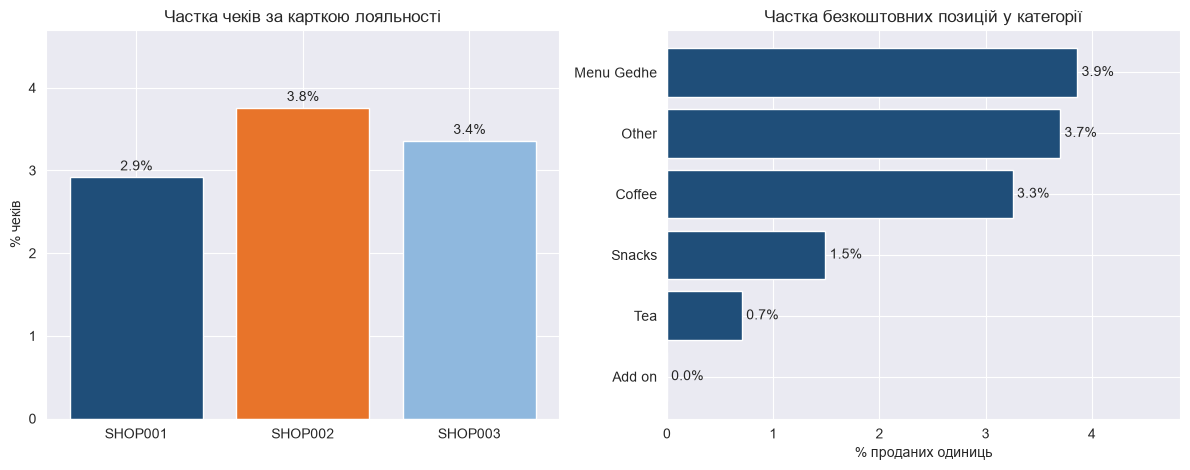

In [54]:
loyalty_outlet = transactions.groupby('Outlet')['UseLoyaltyCard'].mean() * 100
loyalty_cat = (items_df.groupby('Category')['UseLoyaltyCard'].mean() * 100).sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

bars = ax1.bar(loyalty_outlet.index, loyalty_outlet.values, color=[OUTLET_COLORS[o] for o in loyalty_outlet.index])
ax1.bar_label(bars, labels=[f'{v:.1f}%' for v in loyalty_outlet.values], padding=3)
ax1.set_ylim(0, loyalty_outlet.max() * 1.25)
ax1.set_title('Частка чеків за карткою лояльності')
ax1.set_ylabel('% чеків')

bars = ax2.barh(loyalty_cat.index, loyalty_cat.values, color=BLUE)
ax2.bar_label(bars, labels=[f'{v:.1f}%' for v in loyalty_cat.values], padding=3)
ax2.set_xlim(0, loyalty_cat.max() * 1.25)
ax2.set_title('Частка безкоштовних позицій у категорії')
ax2.set_xlabel('% проданих одиниць')

plt.tight_layout()
plt.show()

**Висновок:**
- Програма лояльності «коштує» бізнесу близько **44 млн IDR, або ≈3,3% вартості проданого**: сума помітна, але невелика.
- Найчастіше нею користуються в `SHOP002` (≈3,8% чеків), найрідше в `SHOP001` (≈2,9%).
- Безкоштовними найчастіше стають **кава та Menu Gedhe** (≈3–4% позицій). Чай майже не використовують (≈0,7%), а Add on ніколи. Це ідея для перевірки: можливо, програма недостатньо зрозуміла для клієнтів чайних напоїв.

## 10. Способи оплати
Як клієнти платять і чи відрізняється чек залежно від способу оплати?

In [55]:
pay_df = transactions.groupby('PaymentMethod').agg(
    Receipts=('ReceiptNumber', 'count'),
    Revenue=('TotalAmount', 'sum')
).sort_values('Revenue', ascending=False)

pay_df['Receipts_Share_%'] = pay_df['Receipts'] / pay_df['Receipts'].sum() * 100
pay_df['Revenue_Share_%'] = pay_df['Revenue'] / pay_df['Revenue'].sum() * 100
pay_df['Avg_Check_Paid'] = paid.groupby('PaymentMethod')['TotalAmount'].mean()

display(pay_df)

,Receipts,Revenue,Receipts_Share_%,Revenue_Share_%,Avg_Check_Paid
PaymentMethod,,,,,
BCA,42805,1081473000,79.533631,82.224035,25265.109216
Cash,10913,231061000,20.276849,17.567492,25170.043573
GoFood,102,2742000,0.189521,0.208473,26882.352941


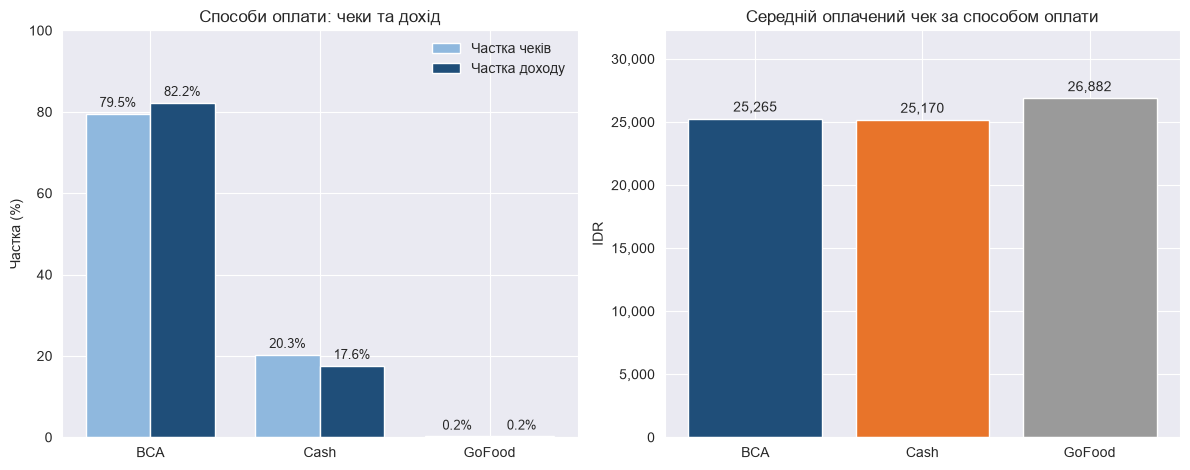

BCA: середній оплачений чек 25,265 IDR, 42,805 чеків
Cash: середній оплачений чек 25,170 IDR, 10,913 чеків
GoFood: середній оплачений чек 26,882 IDR, 102 чеків


In [56]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

x_pay = np.arange(len(pay_df))
w = 0.38
b1 = ax1.bar(x_pay - w / 2, pay_df['Receipts_Share_%'], w, color=LIGHT_BLUE, label='Частка чеків')
b2 = ax1.bar(x_pay + w / 2, pay_df['Revenue_Share_%'], w, color=BLUE, label='Частка доходу')
ax1.bar_label(b1, labels=[f'{v:.1f}%' for v in pay_df['Receipts_Share_%']], padding=3, fontsize=9)
ax1.bar_label(b2, labels=[f'{v:.1f}%' for v in pay_df['Revenue_Share_%']], padding=3, fontsize=9)
ax1.set_xticks(x_pay)
ax1.set_xticklabels(pay_df.index)
ax1.set_ylim(0, 100)
ax1.set_title('Способи оплати: чеки та дохід')
ax1.set_ylabel('Частка (%)')
ax1.legend(frameon=False)

bars = ax2.bar(pay_df.index, pay_df['Avg_Check_Paid'], color=[BLUE, ORANGE, GREY][:len(pay_df)])
ax2.bar_label(bars, labels=[f'{v:,.0f}' for v in pay_df['Avg_Check_Paid']], padding=3)
ax2.set_ylim(0, pay_df['Avg_Check_Paid'].max() * 1.2)
ax2.set_title('Середній оплачений чек за способом оплати')
ax2.set_ylabel('IDR')
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))

plt.tight_layout()
plt.show()

for method in pay_df.index:
    print(f'{method}: середній оплачений чек {pay_df.loc[method, "Avg_Check_Paid"]:,.0f} IDR, {pay_df.loc[method, "Receipts"]:,} чеків')

**Висновок:**
- **BCA (картка) це ≈80% чеків і ≈82% доходу**, готівка ≈20% чеків і ≈18% доходу.
- **GoFood (доставка) майже відсутній:** ≈0,2% чеків (102 замовлення). Канал доставки у цьому бізнесі практично не розвинений.
- Правий графік і рядки під ним порівнюють середній оплачений чек за способами оплати. Якщо різниця між карткою та готівкою невелика, спосіб оплати не впливає на суму покупки. Причини різниці, якщо вона є, у даних не видно.

## 11. Що купують разом
Чи беруть клієнти кілька позицій і які категорії поєднують найчастіше?

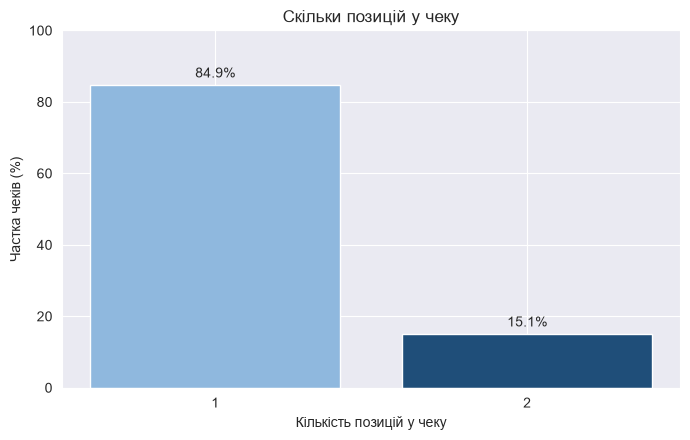

In [57]:
items_per_receipt = transactions['TotalItem'].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(items_per_receipt.index.astype(str), items_per_receipt.values, color=[LIGHT_BLUE, BLUE, ORANGE, GREY][:len(items_per_receipt)])
ax.bar_label(bars, labels=[f'{v:.1f}%' for v in items_per_receipt.values], padding=3)
ax.set_ylim(0, 100)
ax.set_title('Скільки позицій у чеку')
ax.set_xlabel('Кількість позицій у чеку')
ax.set_ylabel('Частка чеків (%)')
plt.tight_layout()
plt.show()

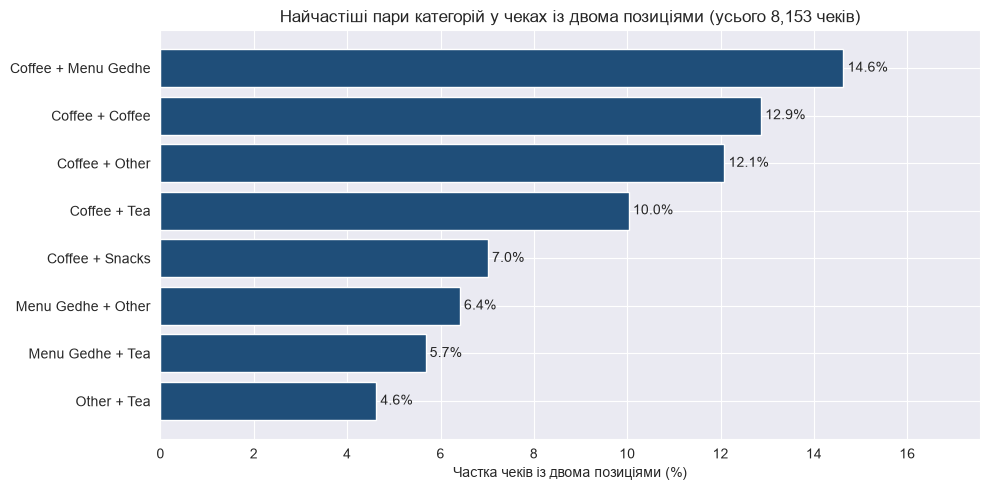

Кава є в 59% чеків із двома позиціями.


In [58]:
# аналізую чеки з двома позиціями: яка пара категорій у чеку
two_items = items_df[items_df['TotalItem'] == 2]
pairs = two_items.groupby('ReceiptNumber')['Category'].apply(lambda s: ' + '.join(sorted(s)))

pair_share = pairs.value_counts(normalize=True).head(8) * 100
plot_df = pair_share.iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(plot_df.index, plot_df.values, color=BLUE)
ax.bar_label(bars, labels=[f'{v:.1f}%' for v in plot_df.values], padding=3)
ax.set_xlim(0, plot_df.max() * 1.2)
ax.set_title(f'Найчастіші пари категорій у чеках із двома позиціями (усього {len(pairs):,} чеків)')
ax.set_xlabel('Частка чеків із двома позиціями (%)')
plt.tight_layout()
plt.show()

print(f'Кава є в {pairs.str.contains("Coffee").mean() * 100:.0f}% чеків із двома позиціями.')

**Висновок:**
- **≈85% чеків містять лише одну позицію**, ≈15% дві. У середньому на чек припадає лише 1,15 позиції.
- Найчастіші пари: **Coffee + Menu Gedhe (≈14,6%)**, Coffee + Coffee (≈12,9%), Coffee + Other (≈12,1%), Coffee + Tea (≈10,0%). **Кава є в більшості пар** (точну частку показує рядок під графіком).
- Пари на рівні окремих товарів дуже розпорошені (найпопулярніша пара зустрілась лише у 8 чеках), тому надійні висновки можна робити тільки на рівні категорій.
- Можлива ідея для перевірки: пропонувати **другу позицію до кави** (випічка, десерт), бо більшість гостей зараз беруть тільки напій.

## 12. Загальні висновки та рекомендації

### Ключові факти
| Тема | Що показують дані |
|---|---|
| Масштаб | 53 820 чеків, 61 973 позиції, ≈1,32 млрд IDR за 9 місяців; середній оплачений чек ≈25 тис. IDR |
| Заклади | `SHOP001` дає ≈49% доходу; середній чек у закладів майже однаковий, тож різниця в кількості гостей |
| Сезонність | пік у червні (≈183 млн IDR), провал у квітні (−27,7%), потім спад до вересня |
| Квітень | просіли `SHOP003` (≈56 → 22 млн) і `SHOP002` (≈26 → 20 млн), `SHOP001` майже без змін |
| Час | сильні години 17–22, слабкі 7–8; дні тижня майже однакові |
| Категорії | Coffee ≈36% доходу; Menu Gedhe дає більше доходу (≈26%), ніж штук (≈20%); Snacks навпаки |
| Лояльність | ≈3,2% чеків, ≈44 млн IDR (≈3,3% вартості проданого); чай майже не використовує програму |
| Оплата | BCA ≈82% доходу; GoFood ≈0,2% |
| Кошик | ≈85% чеків з однією позицією; кава є в більшості пар |

### Ідеї для бізнесу (гіпотези, які варто перевірити)
1. **Збільшити частку чеків із двома позиціями.** Лише ≈15% гостей беруть другу позицію. Навіть невеликий приріст дасть дохід без нових гостей. Перевірити можна комбо-пропозицією «кава + випічка».
2. **Підсилити ранок (7–8 годин).** Це найслабші години в усіх закладах. Варіант: сніданкова пропозиція.
3. **Розібратися з квітнем у `SHOP002` і `SHOP003`.** Спитати бізнес про причину (закриття, ремонт, свята) і перевірити, чи не повториться.
4. **Переглянути програму лояльності для чайних напоїв.** Використання майже нульове, тому, ймовірно, про неї не знають або вона не цікава цій аудиторії.
5. **Для SHOP002 і SHOP003 шукати способи збільшити потік гостей**, бо середній чек уже такий самий, як у лідера.

### Обмеження аналізу
- У даних **немає собівартості**, тому ми аналізуємо дохід, а не прибуток.
- Немає ідентифікатора клієнта, тому не можна порахувати повторні візити та утримання гостей.
- Лише 9 місяців: повну річну сезонність оцінити неможливо.
- Причину квітневого провалу дані не пояснюють, тільки показують, де він стався.
- Ідеї вище це гіпотези: щоб підтвердити їх, потрібен експеримент (наприклад, тест пропозиції в одному закладі).